In [118]:
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.preprocessing import MultiLabelBinarizer
from sklearn.linear_model import LogisticRegression
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, balanced_accuracy_score
from sklearn.pipeline import Pipeline
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay


### Load in the data, define X and y, and split it into train and test sets

In [120]:
df = pd.read_csv('./data/emotions_clean.csv')

In [121]:
# define X and y

X = df['clean_tokens_neg']
X_noneg = df['clean_tokens']
y = df['emotion']



In [122]:
# train test split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=df["emotion"]
)

In [123]:
# train test split without negations
X_train_noneg, X_test_noneg, y_train_noneg, y_test_noneg = train_test_split(
    X_noneg,
    y,
    test_size=0.2,
    random_state=42,
    stratify=df["emotion"]
)

### Hyperparameter tune for the best C value

In [119]:
## Search across values of C using cross validation to find the best hyperparameter
# Perform TFIDF and encode data
pipe = Pipeline([
    ("tfidf", TfidfVectorizer(
        lowercase=True,
        strip_accents="unicode",
        ngram_range=(1, 2),
        min_df=2,
        max_df=0.95,
        sublinear_tf=True
    )),
    ("model", LogisticRegression(
        max_iter=2000,
        class_weight="balanced"
    ))
])

param_grid = {
    "model__C": [0.1, 1, 3, 10]
}

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

search = GridSearchCV(
    estimator=pipe,
    param_grid=param_grid,
    cv=cv,
    scoring="balanced_accuracy",
    n_jobs=-1
)

search.fit(X_train, y_train)

print("Best C:", search.best_params_["model__C"])
print("Best CV balanced accuracy:", round(search.best_score_, 4))


Best C: 1
Best CV balanced accuracy: 0.8688


The best C parameter was 1 with a balanced accuracy of 0.869

### Create logisitic regression pipeline without negation to compare

In [124]:

pipe = Pipeline([
    ("tfidf", TfidfVectorizer(
        lowercase=True,
        strip_accents="unicode",
        ngram_range=(1, 2),
        min_df=2,
        max_df=0.95,
        sublinear_tf=True
    )),
    ("model", LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        C=1.0
    ))
])

pipe.fit(X_train_noneg, y_train_noneg)
y_pred_noneg = pipe.predict(X_test_noneg)

print(classification_report(y_test_noneg, y_pred_noneg, digits=3))
print("Balanced accuracy:", balanced_accuracy_score(y_test_noneg, y_pred_noneg))
print(confusion_matrix(y_test_noneg, y_pred_noneg))


              precision    recall  f1-score   support

       anger      0.878     0.880     0.879       432
        fear      0.887     0.850     0.868       387
         joy      0.933     0.877     0.904      1072
        love      0.667     0.897     0.765       261
     sadness      0.943     0.891     0.916       933
    surprise      0.660     0.896     0.760       115

    accuracy                          0.880      3200
   macro avg      0.828     0.882     0.849      3200
weighted avg      0.891     0.880     0.883      3200

Balanced accuracy: 0.8815839399077267
[[380  11  14   7  19   1]
 [  9 329   9   6   4  30]
 [ 13   5 940  82  19  13]
 [  2   0  18 234   7   0]
 [ 29  17  26  21 831   9]
 [  0   9   1   1   1 103]]


Logistic Regression with TFIDF encoded tokens and no negation resulted in a balanced accuracy of 0.882 and an f1 score of 0.849

### Create a logistic regression pipeline that encodes tokens with TFIDF and uses word pairs

In [106]:

#TF - IDF gives a word a higher value when it appears often in a text and is common across all the text
# Create pipeline for logreg with TFIDF 
pipe = Pipeline([
    ("tfidf", TfidfVectorizer(
        lowercase=True,
        strip_accents="unicode",
        ngram_range=(1, 2),
        min_df=2,
        max_df=0.95,
        sublinear_tf=True
    )),
    ("model", LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        C=1.0
    ))
])

pipe.fit(X_train, y_train)
y_pred = pipe.predict(X_test)

print(classification_report(y_test, y_pred, digits=3))
print("Balanced accuracy:", balanced_accuracy_score(y_test, y_pred))
print(confusion_matrix(y_test, y_pred))



              precision    recall  f1-score   support

       anger      0.874     0.866     0.870       432
        fear      0.876     0.840     0.858       387
         joy      0.924     0.868     0.895      1072
        love      0.665     0.904     0.766       261
     sadness      0.937     0.885     0.910       933
    surprise      0.667     0.904     0.768       115

    accuracy                          0.874      3200
   macro avg      0.824     0.878     0.844      3200
weighted avg      0.885     0.874     0.876      3200

Balanced accuracy: 0.8779804569122839
[[374  11  18   8  20   1]
 [  9 325  12   6   6  29]
 [ 14   6 931  85  24  12]
 [  2   1  17 236   5   0]
 [ 29  19  30  19 826  10]
 [  0   9   0   1   1 104]]


Including negated terms made the model perform worse, reducing balanced accuracy from 0.882 to 0.878 and reducing f1 score from 0.849 to 0.844

### Plot a confusion matrix of results

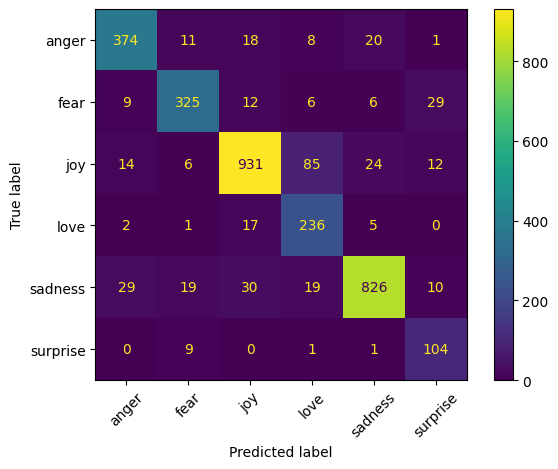

In [125]:
# Plot confusion matrix

labels = sorted(y_test.unique())

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=labels
)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=labels
)

display.plot(xticks_rotation=45)
plt.tight_layout()
plt.show()

### Analyze and Plot Coefficients extracted from Logistic Regression

In [126]:
# Rerun Logistic Regression on the full dataset for coefficient interpretation
pipe_full = Pipeline([
    ("tfidf", TfidfVectorizer(
        lowercase=True,
        strip_accents="unicode",
        ngram_range=(1, 2),
        min_df=2,
        max_df=0.95,
        sublinear_tf=True
    )),
    ("model", LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        C=1.0,
        random_state=42
    ))
])

pipe_full.fit(X, y)
model = pipe_full.named_steps["model"]
vectorizer = pipe_full.named_steps["tfidf"]
feature_names = vectorizer.get_feature_names_out()

In [127]:
# extract top positive and negative coefficients for each class
for i, cls in enumerate(model.classes_):
    weights = pd.DataFrame({
        "Feature": feature_names,
        "Coefficient": model.coef_[i],
        "Class": cls
    })

    top_positive = weights.sort_values("Coefficient", ascending=False).head(10)
    top_negative = weights.sort_values("Coefficient", ascending=True).head(10)

    print(f"\nClass: {cls}")
    print("Top positive coefficients:")
    print(top_positive)
    print("\nTop negative coefficients:")
    print(top_negative)


Class: anger
Top positive coefficients:
            Feature  Coefficient  Class
2187      dangerous     5.192904  anger
10886          rude     4.864979  anger
6319      irritable     4.857160  anger
5343         greedy     4.696604  anger
2604   dissatisfied     4.647166  anger
952          bitchy     4.594023  anger
9786          petty     4.529497  anger
11142       selfish     4.484728  anger
2030         cranky     4.404170  anger
13529       violent     4.392318  anger

Top negative coefficients:
           Feature  Coefficient  Class
13883        weird    -2.340146  anger
11895      strange    -2.224143  anger
9423   overwhelmed    -2.071037  anger
299         amazed    -1.677927  anger
12168    surprised    -1.659633  anger
2121       curious    -1.647295  anger
9546    passionate    -1.634344  anger
304        amazing    -1.622036  anger
802        beloved    -1.601154  anger
4860         funny    -1.585632  anger

Class: fear
Top positive coefficients:
            Feature  C

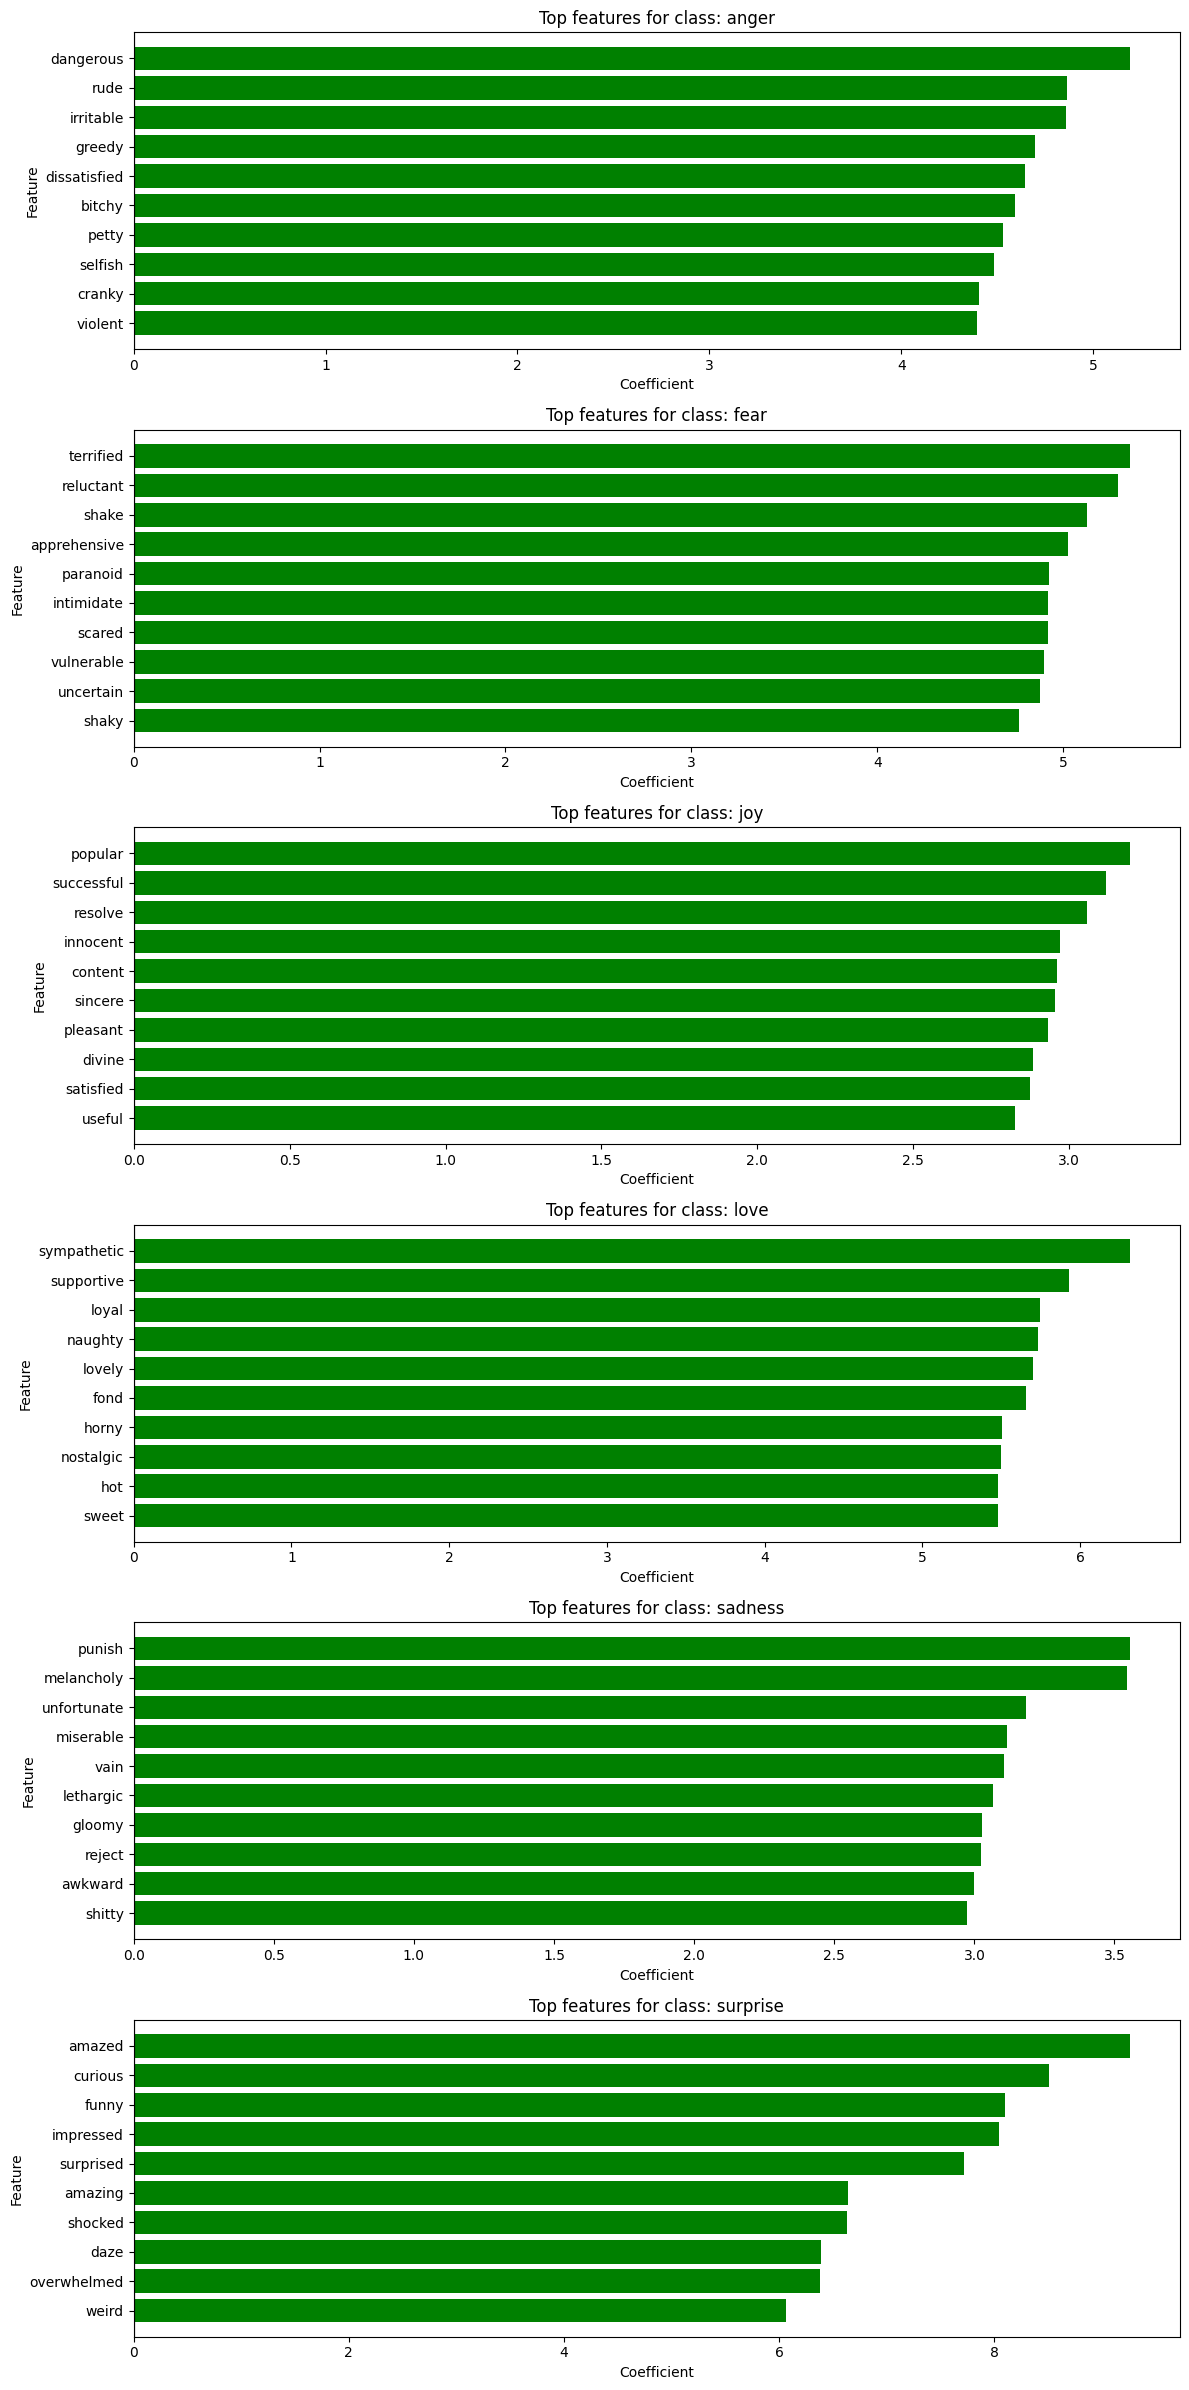

In [128]:
# plot the largest coefficients per class
feature_names = vectorizer.get_feature_names_out()
class_names = model.classes_
top_n = 10

all_rows = []

for i, cls in enumerate(class_names):
    coef = model.coef_[i]
    df_cls = pd.DataFrame({
        "feature": feature_names,
        "coef": coef,
        "class": cls
    })
    df_cls["abs_coef"] = df_cls["coef"].abs()
    all_rows.append(df_cls.sort_values("abs_coef", ascending=False).head(top_n))

top_features = pd.concat(all_rows, ignore_index=True)

n_classes = len(class_names)
fig, axes = plt.subplots(n_classes, 1, figsize=(12, 4 * n_classes))

for ax, cls in zip(axes, class_names):
    df_cls = top_features[top_features["class"] == cls].sort_values("coef", ascending=False)

    colors = ["green" if v >= 0 else "red" for v in df_cls["coef"]]
    ax.barh(df_cls["feature"], df_cls["coef"], color=colors)
    ax.axvline(0, color="black", linewidth=0.8)
    ax.set_title(f"Top features for class: {cls}")
    ax.invert_yaxis()
    ax.set_xlabel("Coefficient")
    ax.set_ylabel("Feature")

plt.tight_layout()
plt.show()

In [129]:
df_cls

,feature,coef,class,abs_coef
50,amazed,9.265627,surprise,9.265627
51,curious,8.509022,surprise,8.509022
52,funny,8.106083,surprise,8.106083
53,impressed,8.049467,surprise,8.049467
54,surprised,7.722202,surprise,7.722202
55,amazing,6.643334,surprise,6.643334
56,shocked,6.636808,surprise,6.636808
57,daze,6.394856,surprise,6.394856
58,overwhelmed,6.383471,surprise,6.383471
59,weird,6.061481,surprise,6.061481


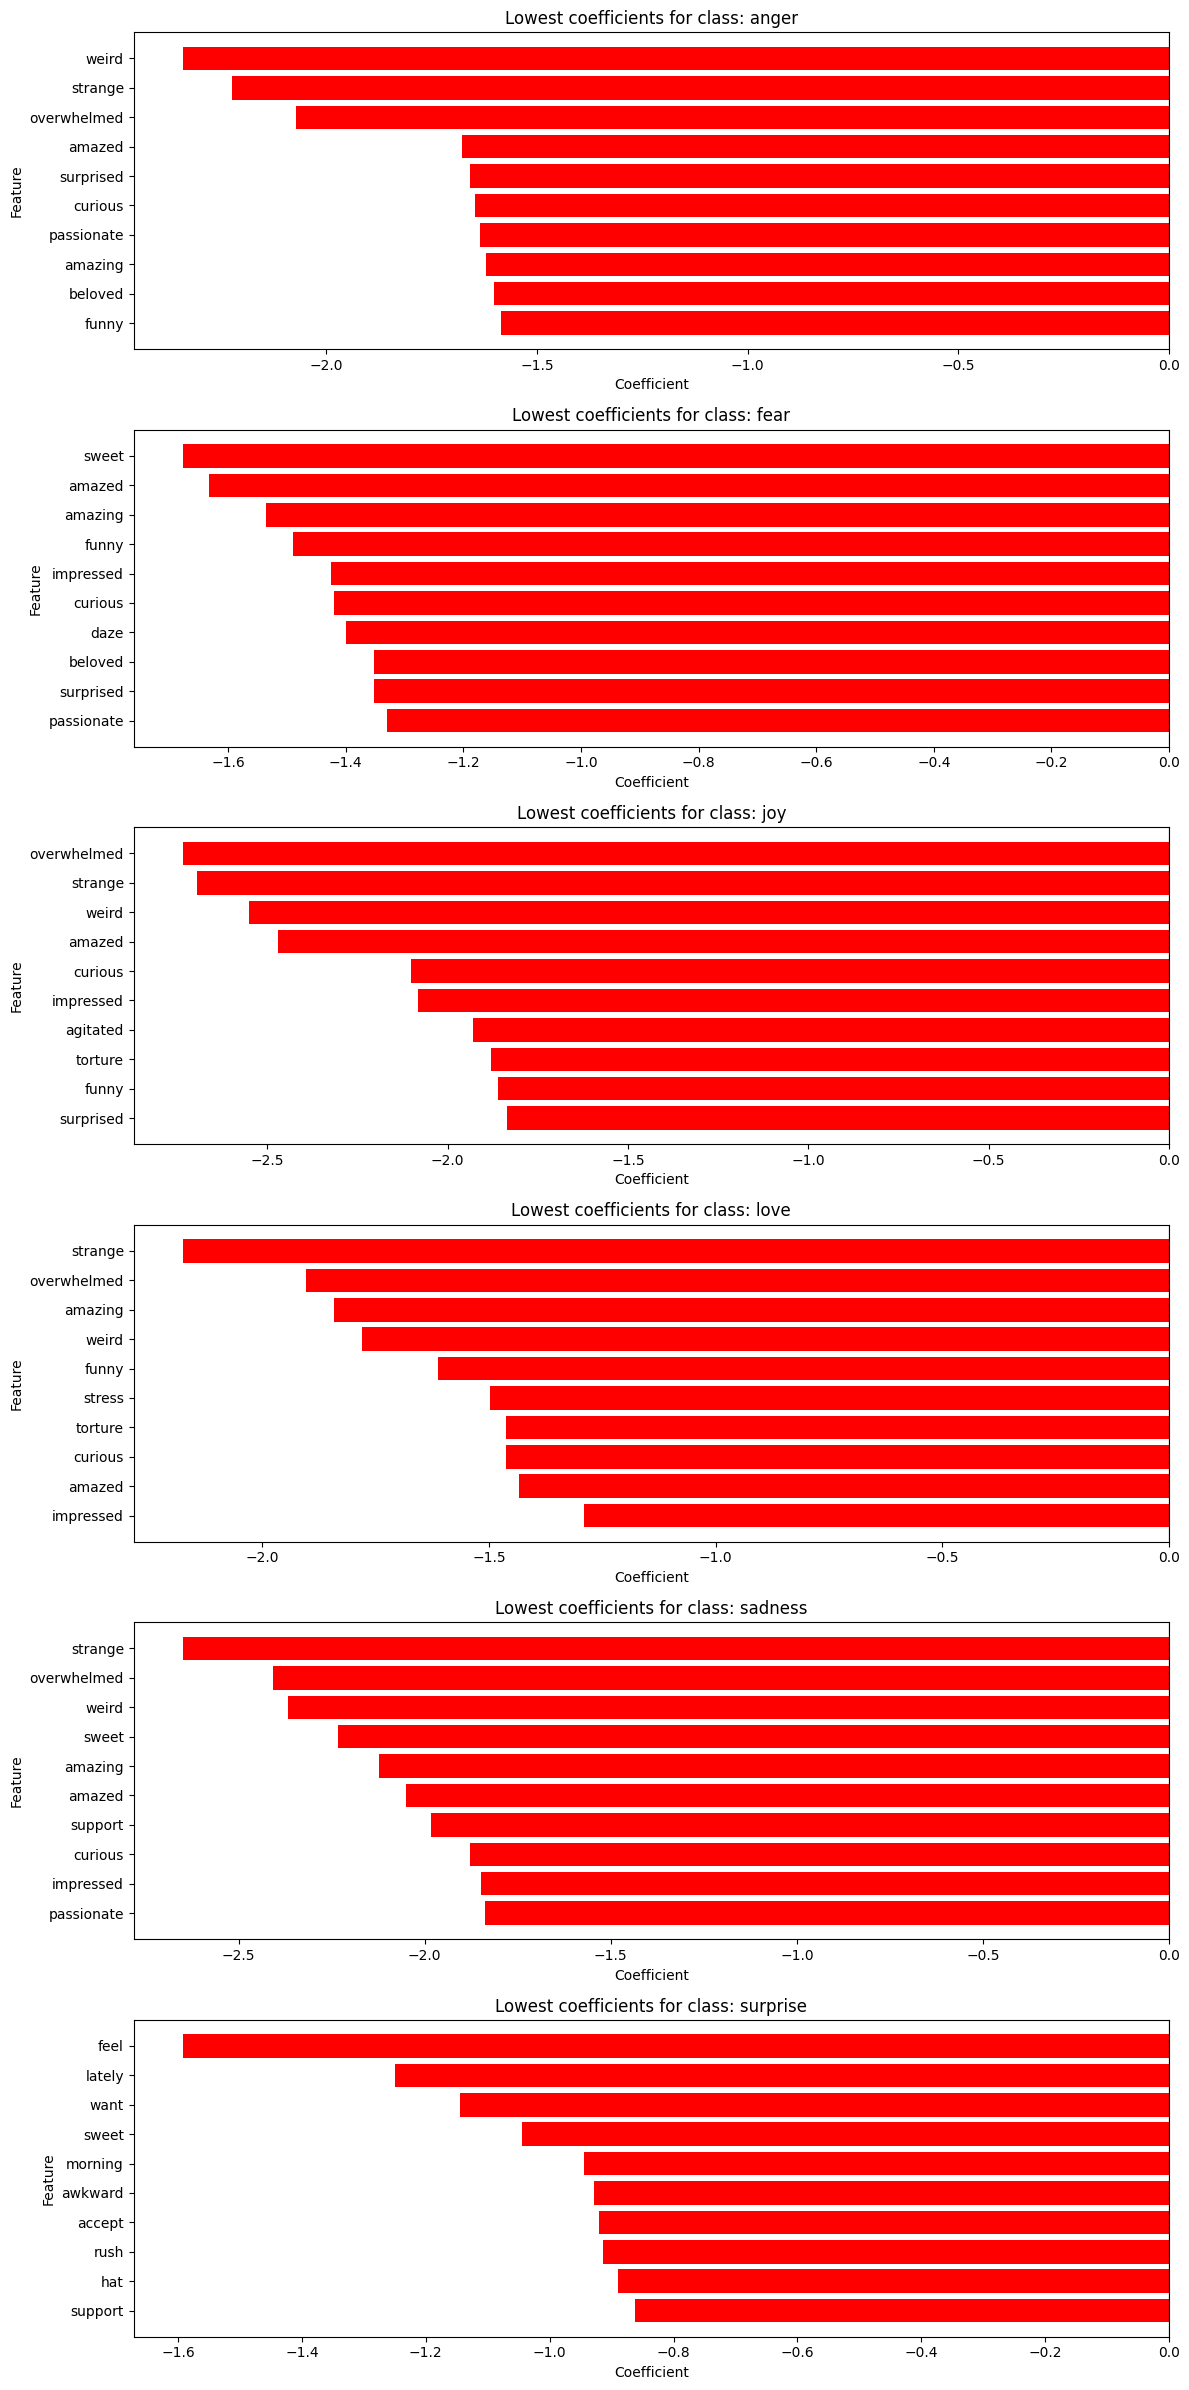

In [130]:
# Plot most negative coefficients
feature_names = vectorizer.get_feature_names_out()
class_names = model.classes_
top_n = 10

all_rows = []

for i, cls in enumerate(class_names):
    coef = model.coef_[i]
    df_cls = pd.DataFrame({
        "feature": feature_names,
        "coef": coef,
        "class": cls
    })
    df_cls["abs_coef"] = df_cls["coef"].abs()
    df_cls = df_cls.sort_values("coef", ascending=True).head(top_n)
    all_rows.append(df_cls)

low_features = pd.concat(all_rows, ignore_index=True)

n_classes = len(class_names)
fig, axes = plt.subplots(n_classes, 1, figsize=(12, 4 * n_classes))

for ax, cls in zip(axes, class_names):
    df_cls = low_features[low_features["class"] == cls].sort_values("coef", ascending=True)

    colors = ["green" if v >= 0 else "red" for v in df_cls["coef"]]
    ax.barh(df_cls["feature"], df_cls["coef"], color=colors)
    ax.axvline(0, color="black", linewidth=0.8)
    ax.set_title(f"Lowest coefficients for class: {cls}")
    ax.invert_yaxis()
    ax.set_xlabel("Coefficient")
    ax.set_ylabel("Feature")

plt.tight_layout()
plt.show()

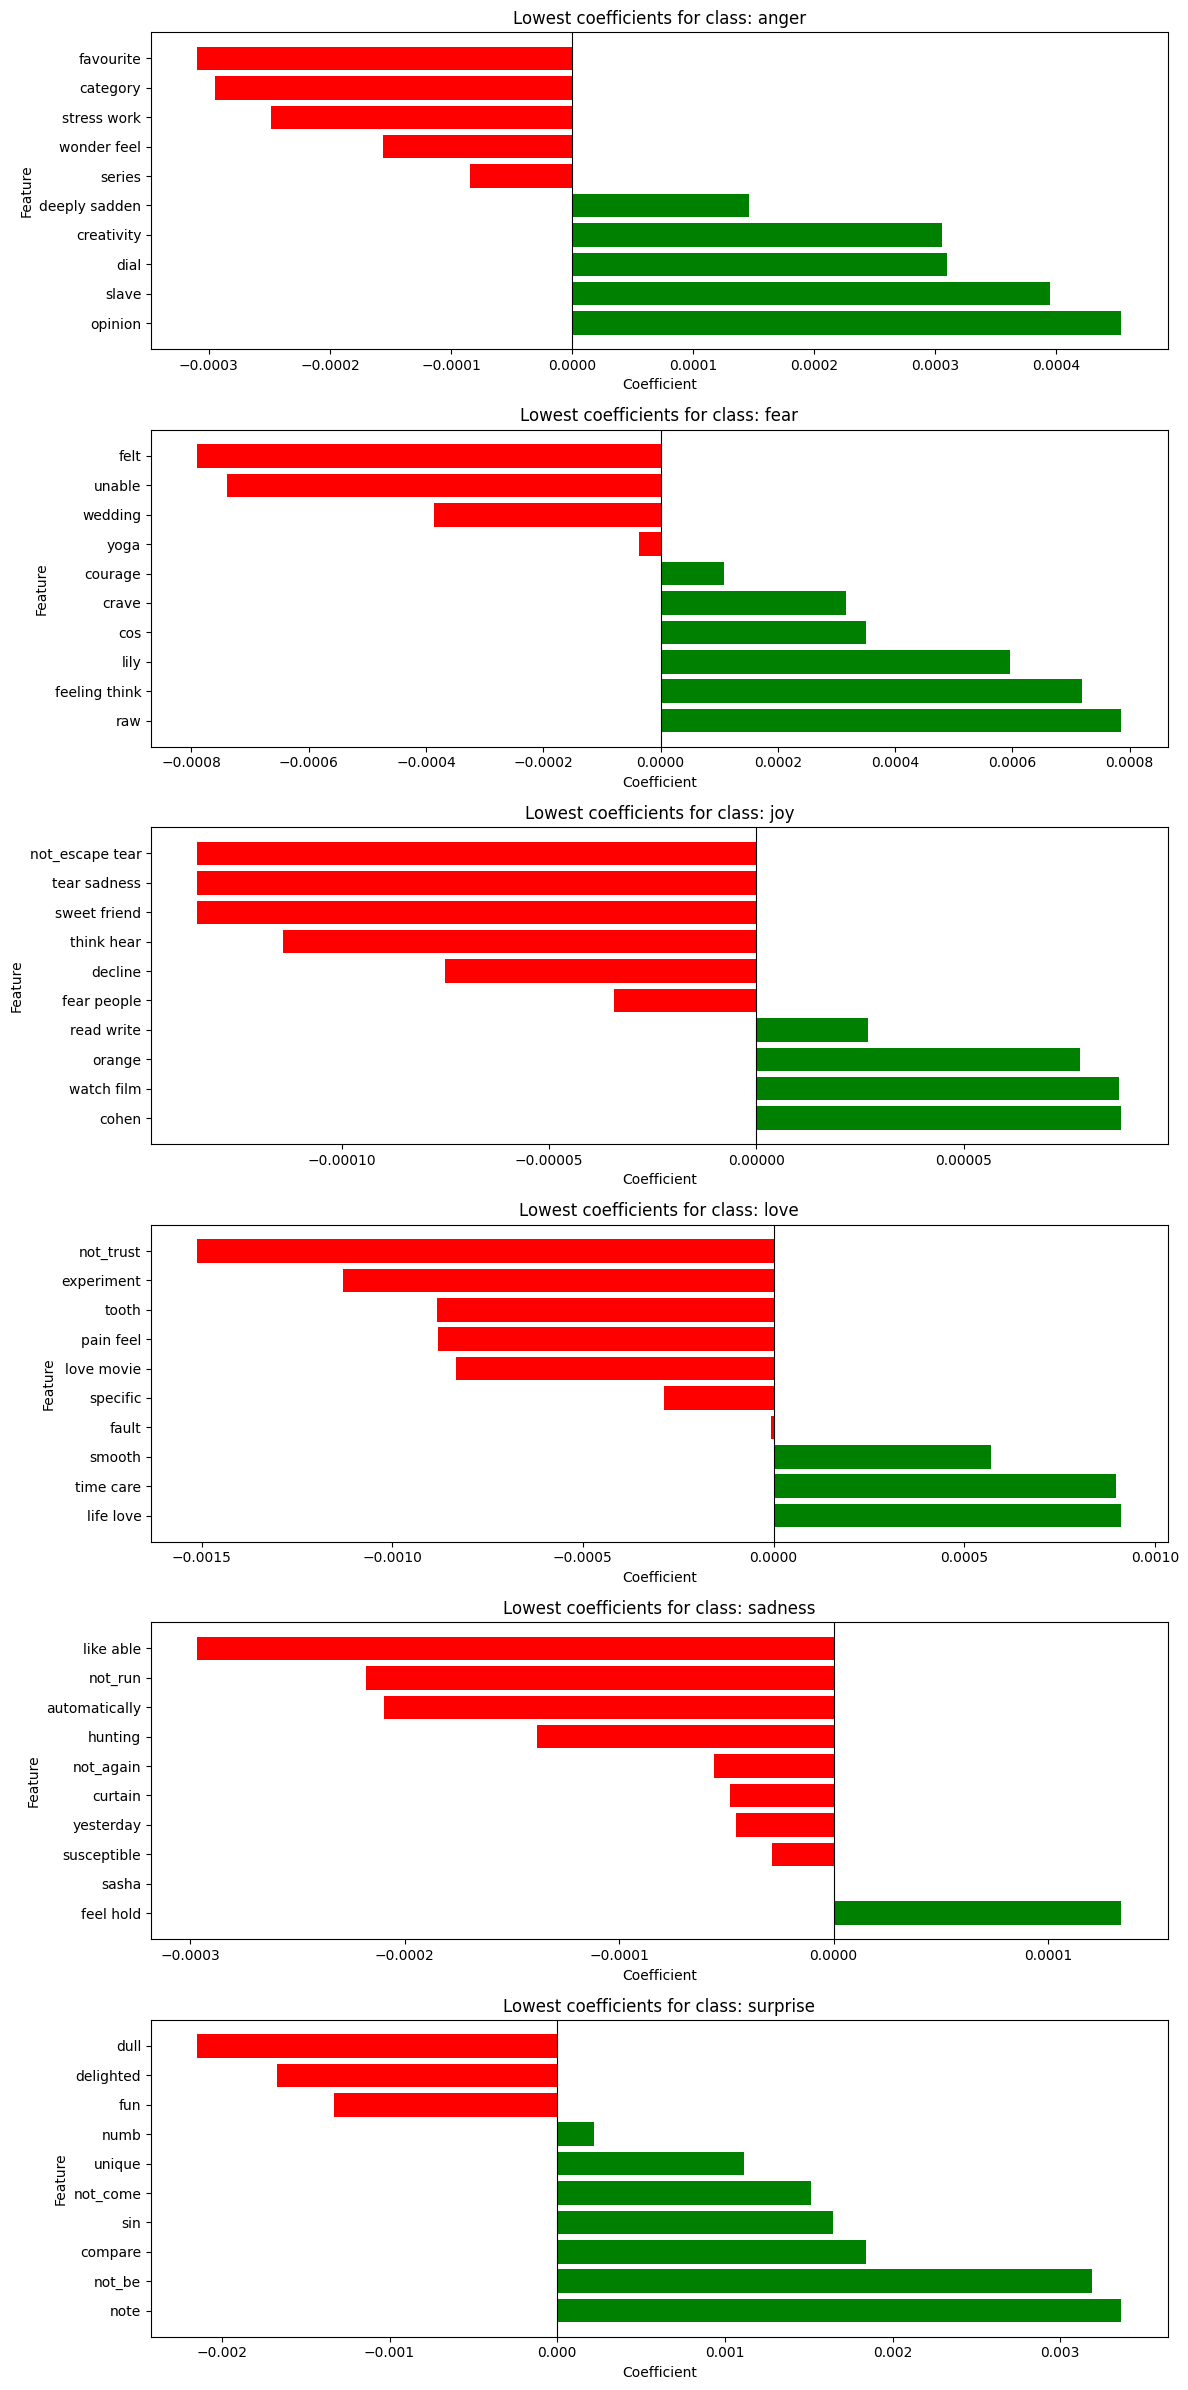

In [131]:
# Plot smallest coefficients
feature_names = vectorizer.get_feature_names_out()
class_names = model.classes_
top_n = 10

all_rows = []

for i, cls in enumerate(class_names):
    coef = model.coef_[i]
    df_cls = pd.DataFrame({
        "feature": feature_names,
        "coef": coef,
        "class": cls
    })
    df_cls["abs_coef"] = df_cls["coef"].abs()
    df_cls = df_cls.sort_values("abs_coef", ascending=True).head(top_n)
    all_rows.append(df_cls)

low_features = pd.concat(all_rows, ignore_index=True)

n_classes = len(class_names)
fig, axes = plt.subplots(n_classes, 1, figsize=(12, 4 * n_classes))

for ax, cls in zip(axes, class_names):
    df_cls = low_features[low_features["class"] == cls].sort_values("coef", ascending=True)

    colors = ["green" if v >= 0 else "red" for v in df_cls["coef"]]
    ax.barh(df_cls["feature"], df_cls["coef"], color=colors)
    ax.axvline(0, color="black", linewidth=0.8)
    ax.set_title(f"Lowest coefficients for class: {cls}")
    ax.invert_yaxis()
    ax.set_xlabel("Coefficient")
    ax.set_ylabel("Feature")

plt.tight_layout()
plt.show()

### Find Coefficients for Specific Words

In [132]:
# find coefficients for a specific word
# choose a word
word = "good"

# get feature index
feature_names = vectorizer.get_feature_names_out()
word_idx = np.where(feature_names == word)[0][0]

# coefficients for this word across all classes
coef_table = pd.DataFrame({
    "class": model.classes_,
    "coefficient": model.coef_[:, word_idx]
})

print(coef_table.sort_values("coefficient", ascending=False))

      class  coefficient
2       joy     1.400425
3      love     0.046459
4   sadness    -0.029657
5  surprise    -0.405265
0     anger    -0.408722
1      fear    -0.603240


In [133]:
# define top 20 words
top_20_words = df['adjectives'].explode()

# remove empty/placeholder values
top_20_words = top_20_words[top_20_words.notna()]

# strip brackets and quotes
top_20_words = top_20_words.str.replace(r"[\[\]'\"]", "", regex=True)

# remove empty strings
top_20_words = top_20_words[top_20_words != ""]

# count words
top_20_words = top_20_words.value_counts().head(20)
for word in top_20_words.index:
    print(word)
    feature_names = vectorizer.get_feature_names_out()
    word_idx = np.where(feature_names == word)[0][0]

    # coefficients for this word across all classes
    coef_table = pd.DataFrame({
        "class": model.classes_,
        "coefficient": model.coef_[:, word_idx]
    })

    print(coef_table.sort_values("coefficient", ascending=False))

good
      class  coefficient
2       joy     1.400425
3      love     0.046459
4   sadness    -0.029657
5  surprise    -0.405265
0     anger    -0.408722
1      fear    -0.603240
sweet
      class  coefficient
3      love     5.476345
2       joy     0.734975
5  surprise    -1.045508
0     anger    -1.254917
1      fear    -1.676970
4   sadness    -2.233924
little
      class  coefficient
1      fear     0.734917
5  surprise     0.710976
0     anger    -0.029412
3      love    -0.276475
2       joy    -0.556601
4   sadness    -0.583404
strange
      class  coefficient
5  surprise     6.053166
1      fear     3.690004
3      love    -2.174749
0     anger    -2.224143
4   sadness    -2.649466
2       joy    -2.694812
amazing
      class  coefficient
5  surprise     6.643334
2       joy     0.480125
1      fear    -1.535618
0     anger    -1.622036
3      love    -1.842647
4   sadness    -2.123158
overwhelmed
      class  coefficient
5  surprise     6.383471
1      fear     2.731416
3   

Hi Anita, this is a test